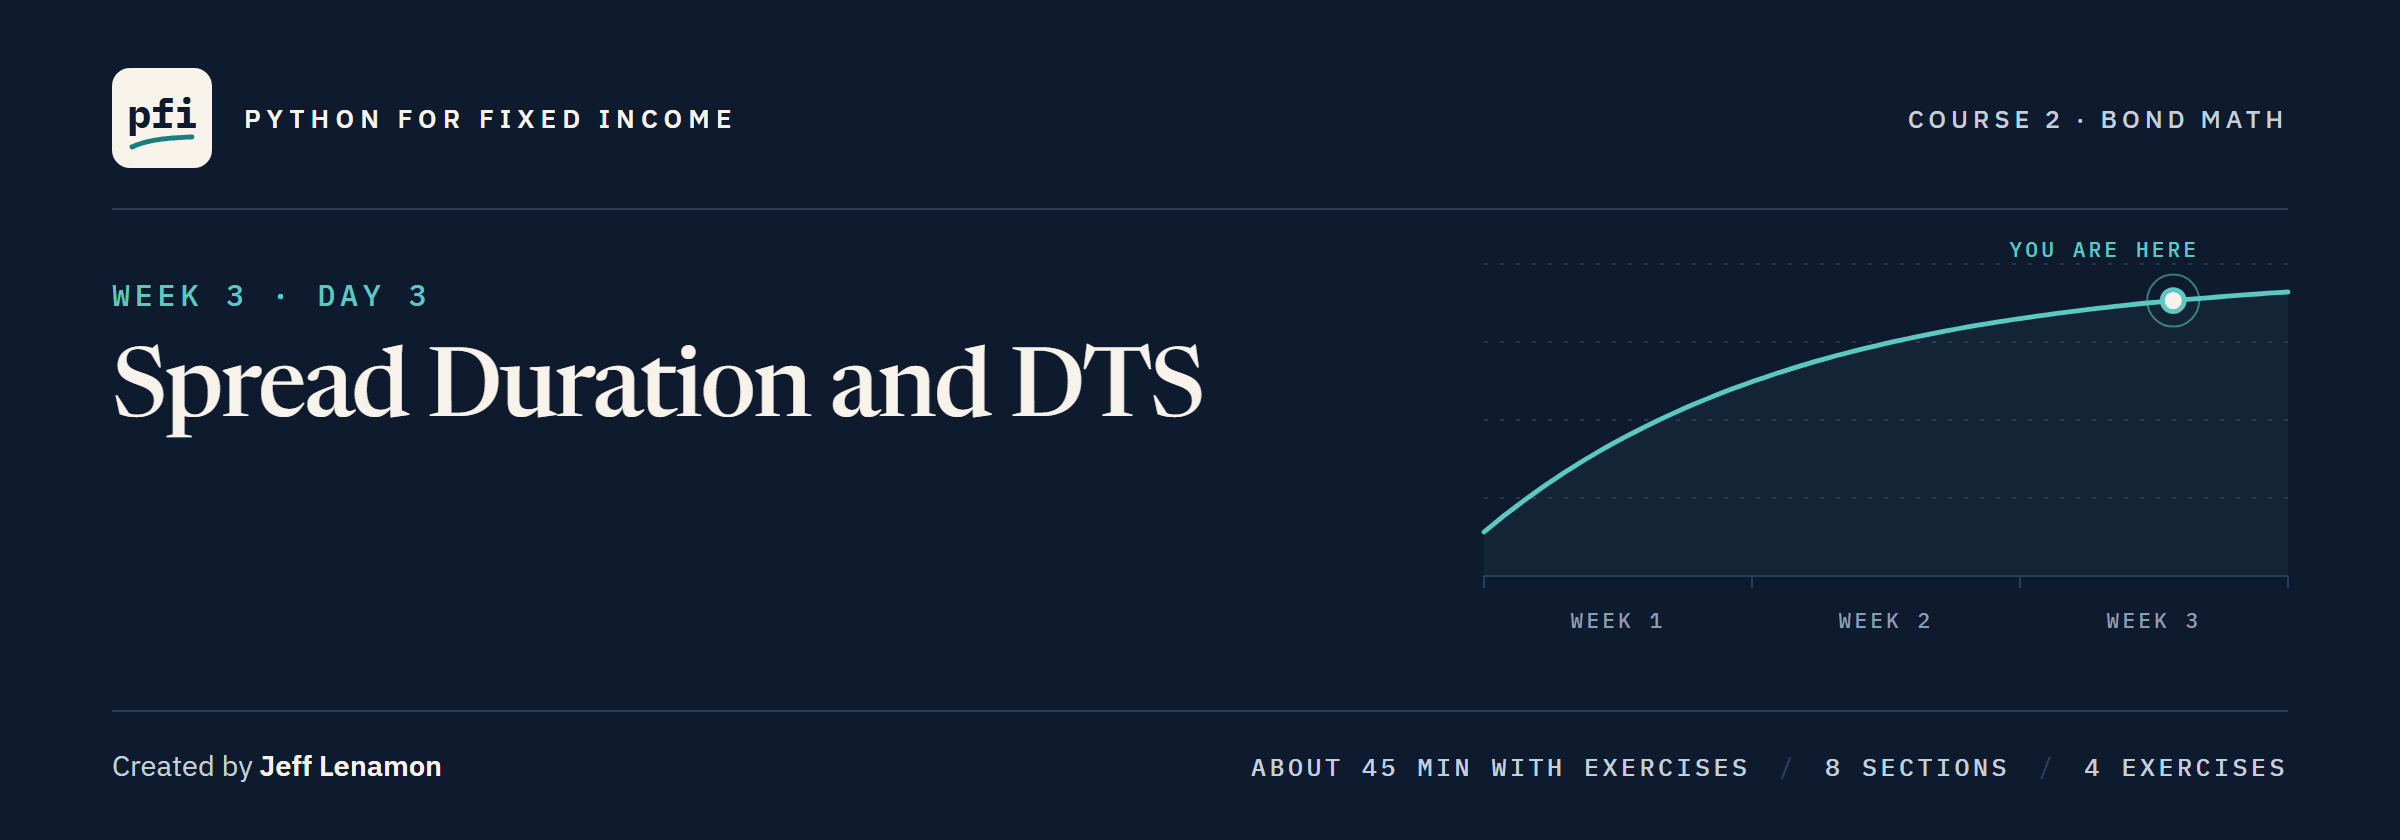

# Spread Duration and DTS

Week 3, Day 3. Spread duration measured by moving the spread and repricing, DTS built from it, and the book's spread risk by rating bucket.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day3/13_spread_duration_and_dts.ipynb)

### The Desk Lead's Note

> Two more columns of our month-end file: `spread_duration` and `dts`. In every one of the 200 rows `spread_duration` is the same number as `duration`. A copy error? Rebuild both columns from the bond math, and tell me how the book's DTS splits by rating bucket.

The issuers are invented; every number describes the data.

**Measure one bond's spread duration first, then answer the question about the copy.**

## Your Route Through Day 3

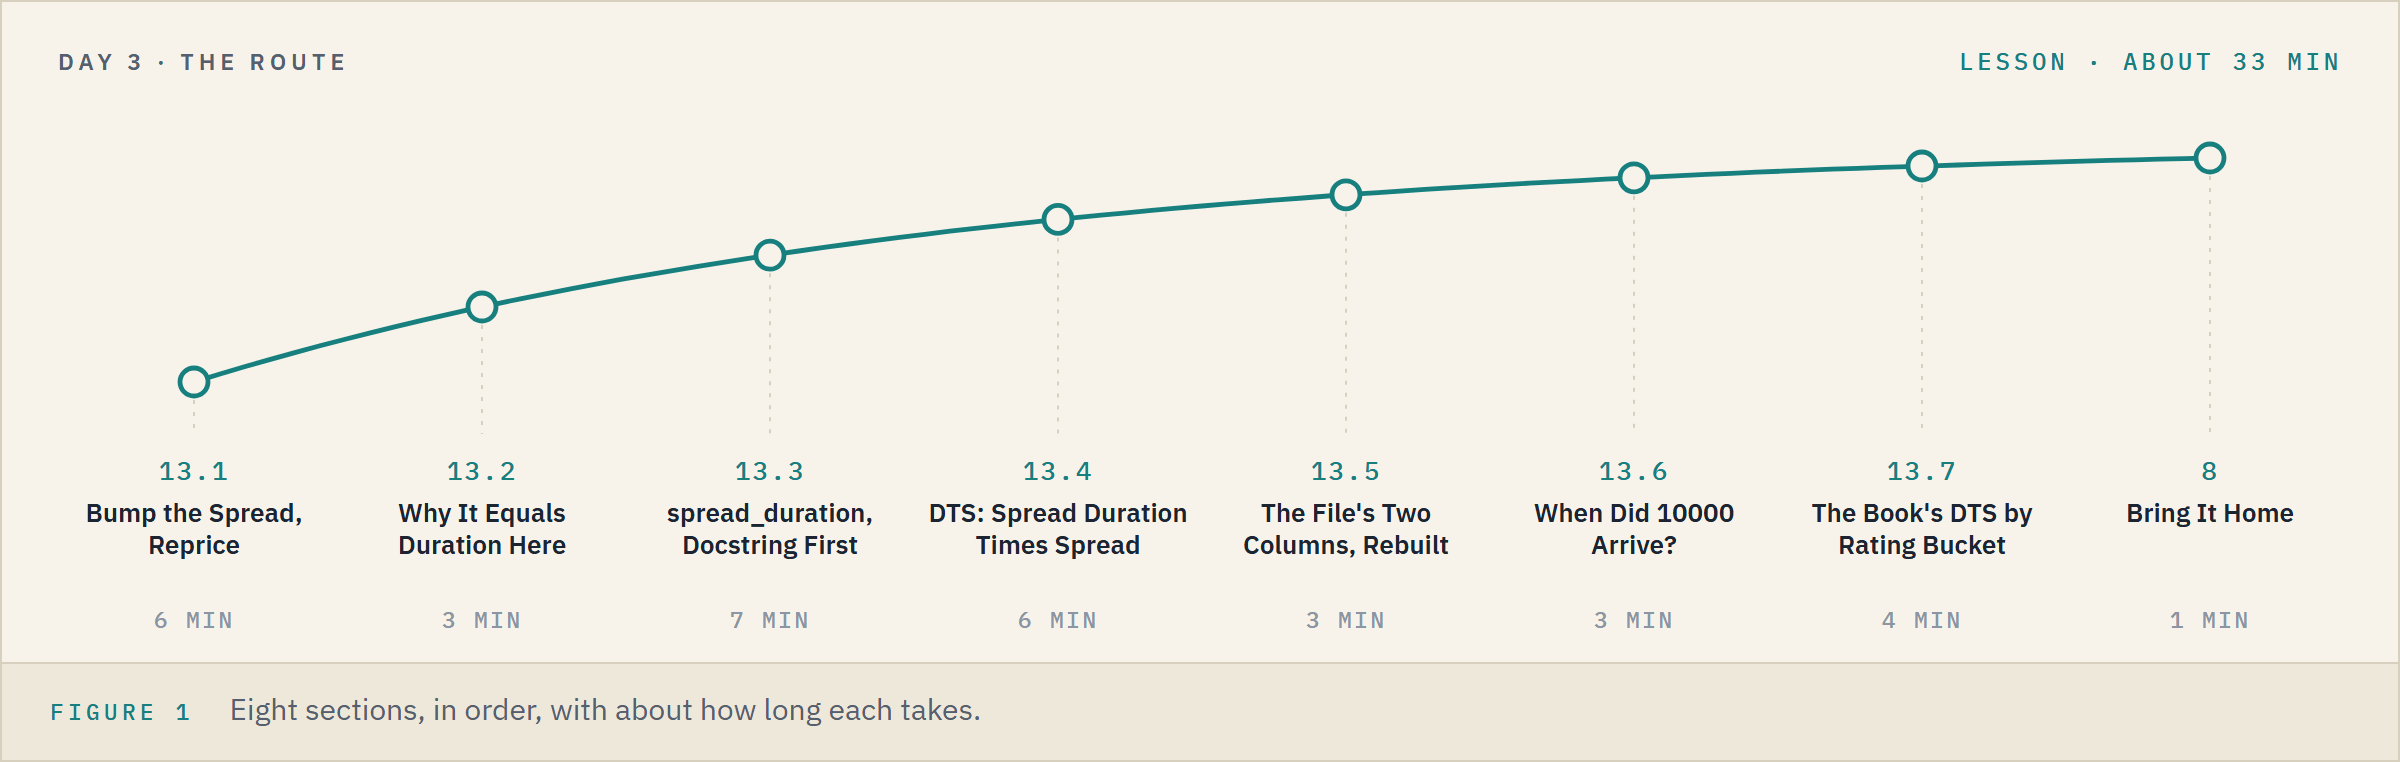

**Time.** About 33 minutes for the lesson, then about 12 for the four exercises.

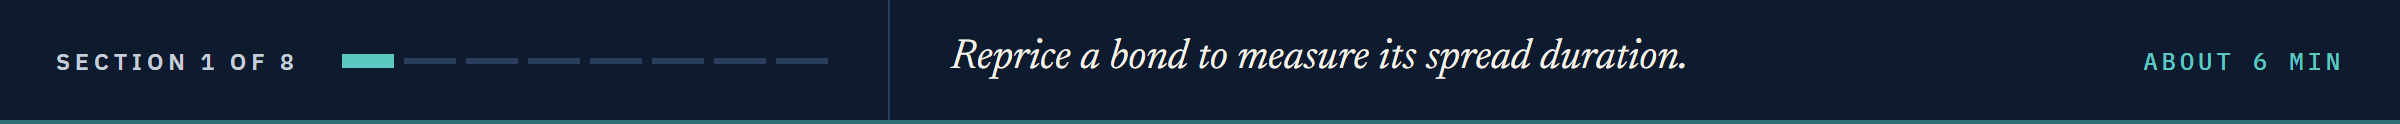

## 13.1 Bump the Spread, Reprice

### Make Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 12 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(13)

Work folder pfi_course2_13_k4w7q2xr: 5 data files, the module as notebook 12 left it, 12 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................                                      [100%]
35 passed in 0.50s



### Import the Module and the Libraries

In [3]:
import bondmath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### Read the Book

Q. Is `spread_duration` really the same as `duration` in every row?

In [4]:
holdings = pd.read_csv('holdings.csv')
# bondmath takes datetime.date values, as in notebook 06
holdings['as_of_date'] = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['maturity'] = pd.to_datetime(holdings['maturity']).dt.date
same = (holdings['spread_duration'] == holdings['duration']).sum()
print(f'spread_duration equals duration in {same} of {len(holdings)} rows')
holdings[['cusip', 'issuer', 'oas', 'duration', 'spread_duration', 'dts']].head()

spread_duration equals duration in 200 of 200 rows


,cusip,issuer,oas,duration,spread_duration,dts
0,99080CAE8,Bezane Finance,147,4.627,4.627,680.2
1,99049XAE2,Bezamyth Machinery,535,2.165,2.165,1158.3
2,99039NAC0,Bezoquil Freight,153,3.250,3.250,497.2
3,99039NAG1,Bezoquil Freight,218,12.113,12.113,2640.6
4,99034IAD4,Bezorin Finance,127,7.338,7.338,931.9


`oas` is the spread notebook 12 rebuilt from the curve, to 2.3e-13 bp.

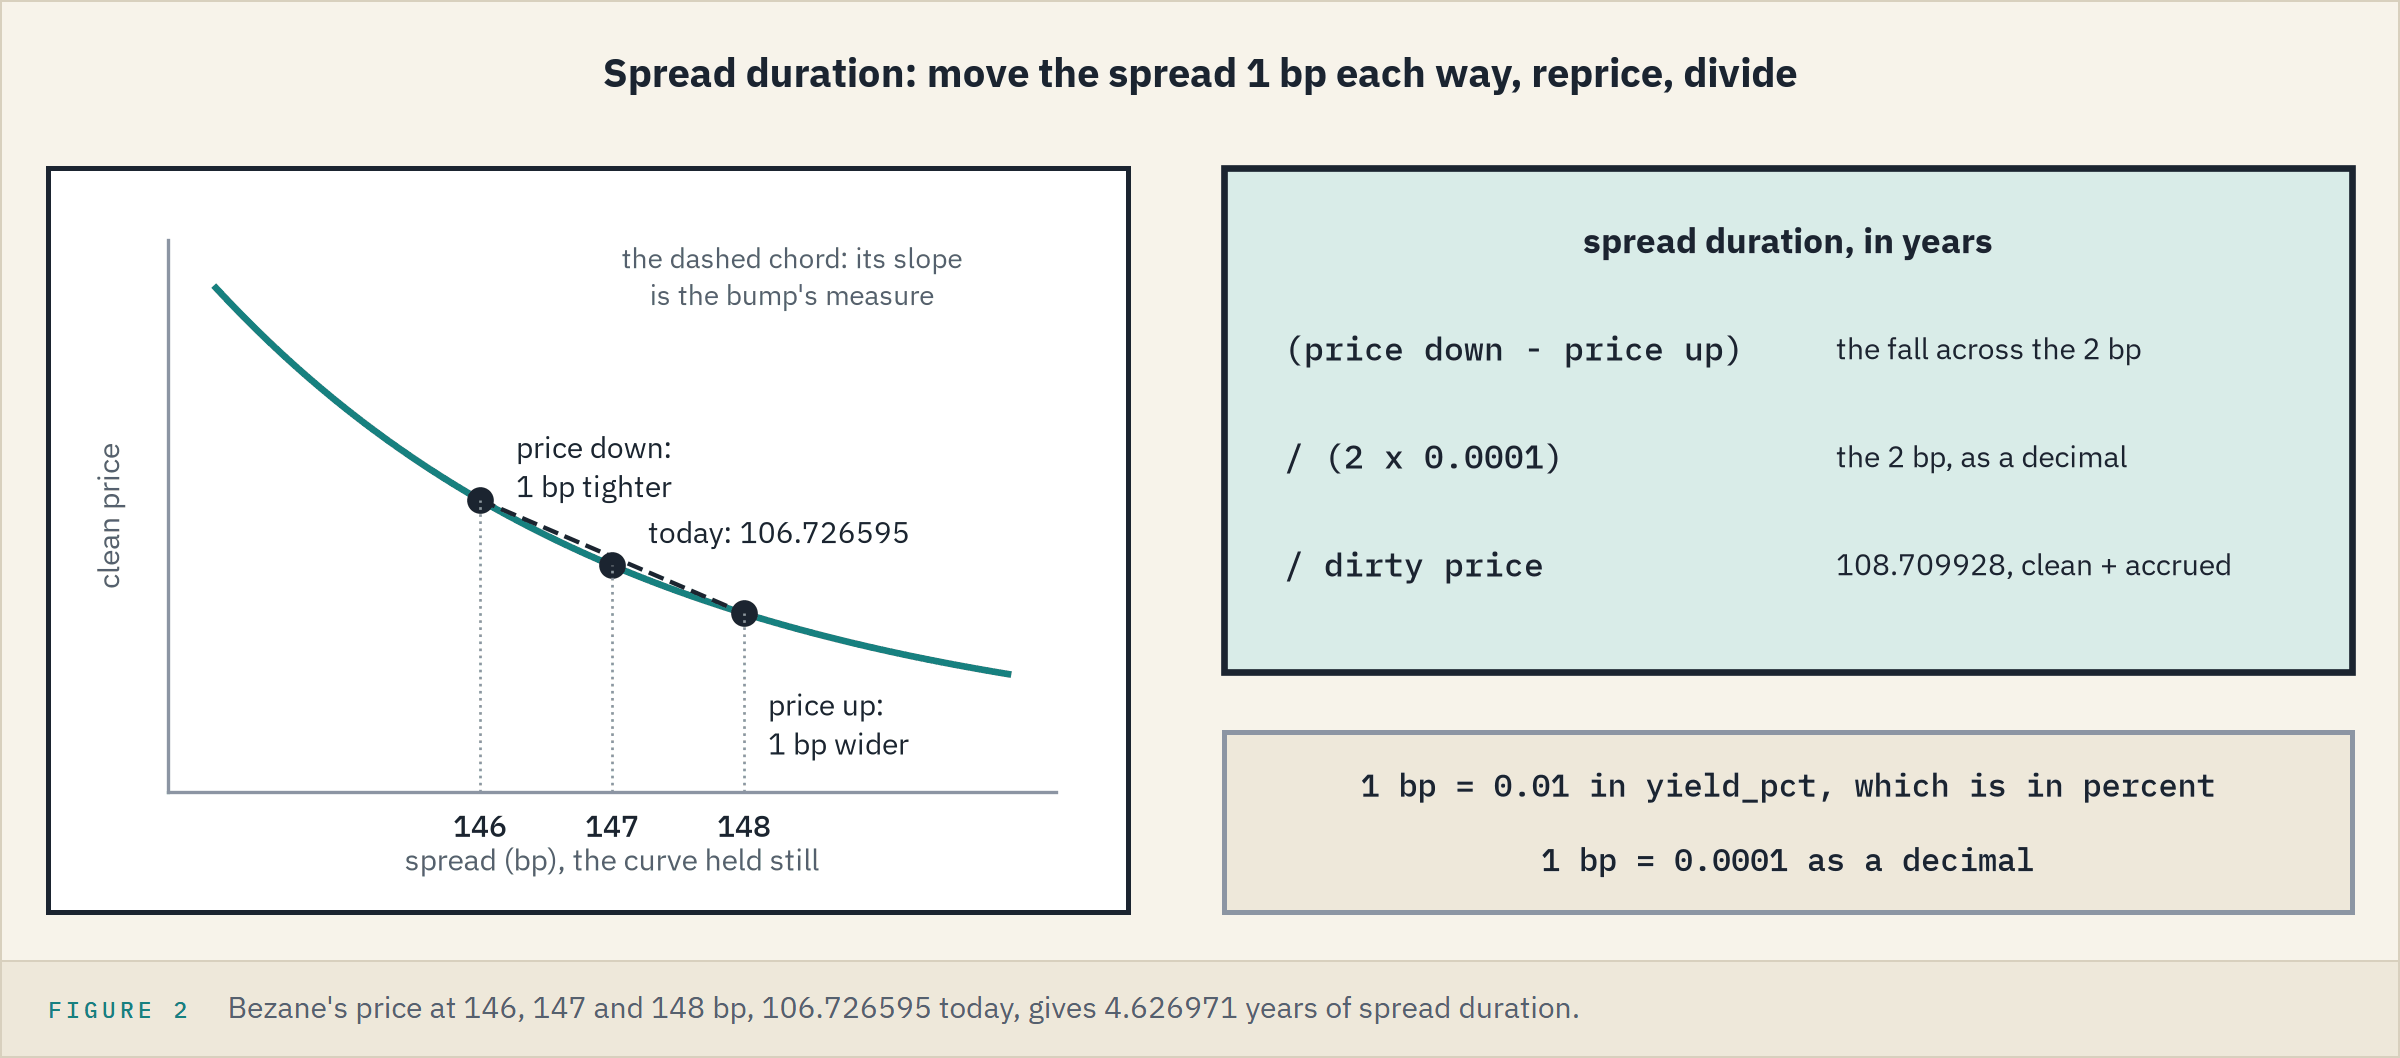

**Spread duration** is the percent the price moves for 100 bp of spread, in years.
It is measured the way notebook 09 checked DV01: move the input 1 bp each way and reprice.
The file's yield is the curve plus the spread, so with the curve held still, a move in the spread moves the yield.
The pieces:

* price down and price up: the clean price with the spread 1 bp tighter and 1 bp wider
* 2 x 0.0001: the 2 bp between them, as a decimal
* the dirty price today: clean plus accrued

### Bezane Finance

Q. What are the first bond's terms?

In [5]:
bezane = holdings.iloc[0]
settlement, maturity = bezane['as_of_date'], bezane['maturity']
coupon_pct, yield_pct, spread_bp = bezane['coupon'], bezane['yield_pct'], bezane['oas']
print(f"{bezane['issuer']}: {coupon_pct} percent coupon, maturing {maturity}")
print(f'yield {yield_pct} percent, spread {spread_bp} bp')

Bezane Finance: 7.0 percent coupon, maturing 2032-06-18
yield 5.606 percent, spread 147 bp


**Predict 1**

Q. Bezane's spread widens 1 bp and the curve stays put. How far does its clean price fall, in points per 100 of face? Write down a number.

### Bezane, 1 bp Each Way

In [6]:
# 1 bp of spread is 0.01 in yield_pct, which is in percent
price_down = bondmath.price(settlement, maturity, coupon_pct, yield_pct - 0.01)
price_up = bondmath.price(settlement, maturity, coupon_pct, yield_pct + 0.01)
price_today = bondmath.price(settlement, maturity, coupon_pct, yield_pct)
print(f'1 bp tighter {price_down:.6f}, today {price_today:.6f}, 1 bp wider {price_up:.6f}')
print(f'the fall for 1 bp wider: {price_today - price_up:.4f} per 100')

1 bp tighter 106.776909, today 106.726595, 1 bp wider 106.676310
the fall for 1 bp wider: 0.0503 per 100


To four decimals that is the bond's DV01 (notebook 09's `dv01`), here from a move in the spread.

### From a Slope to Years

Q. Divide the slope by the dirty price.

In [7]:
dirty = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
# the 2 bp between the two prices, as a decimal: 2 x 0.0001
spread_duration_years = (price_down - price_up) / (2 * 0.0001) / dirty
print(f'dirty price {dirty:.6f}; spread duration {spread_duration_years:.6f} years')

dirty price 108.709928; spread duration 4.626971 years


Accrued interest does not move with the spread, so the clean prices' difference is the dirty prices' difference.

**Excel side by side.** Tested in Excel for Bezane, one cell each.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Price at the yield (B1)</td><td align="left"><code>bondmath.price(settlement, maturity, coupon_pct, yield_pct)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100,100,2,0)</code></td><td align="left">106.72659513009698</td></tr>
<tr><td align="left">Spread 1 bp tighter (B2)</td><td align="left"><code>price_down</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100-0.0001,100,2,0)</code></td><td align="left">106.77690922344026</td></tr>
<tr><td align="left">Spread 1 bp wider (B3)</td><td align="left"><code>price_up</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100+0.0001,100,2,0)</code></td><td align="left">106.67630969052466</td></tr>
<tr><td align="left">Accrued (B4)</td><td align="left"><code>bondmath.accrued_interest(settlement, maturity, coupon_pct)</code></td><td align="left"><code>=100*7/100/2*COUPDAYBS(DATE(2026,9,30),DATE(2032,6,18),2,0)/COUPDAYS(DATE(2026,9,30),DATE(2032,6,18),2,0)</code></td><td align="left">1.9833333333333334</td></tr>
<tr><td align="left">Spread duration (B5)</td><td align="left"><code>spread_duration_years</code></td><td align="left"><code>=(B2-B3)/(2*0.0001)/(B1+B4)</code></td><td align="left">4.626970799149981</td></tr>
</table>
<br clear="left">

Inside `PRICE` the yield is a decimal, so 1 bp is `0.0001` there and in the slope alike.

**Bezane's price moves about 4.63 percent of its value for 100 bp of spread: spread duration is 4.626971 years.**

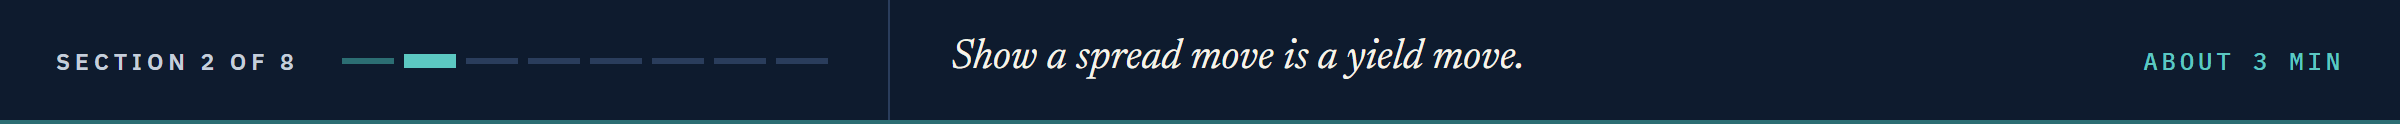

## 13.2 Why It Equals Duration Here

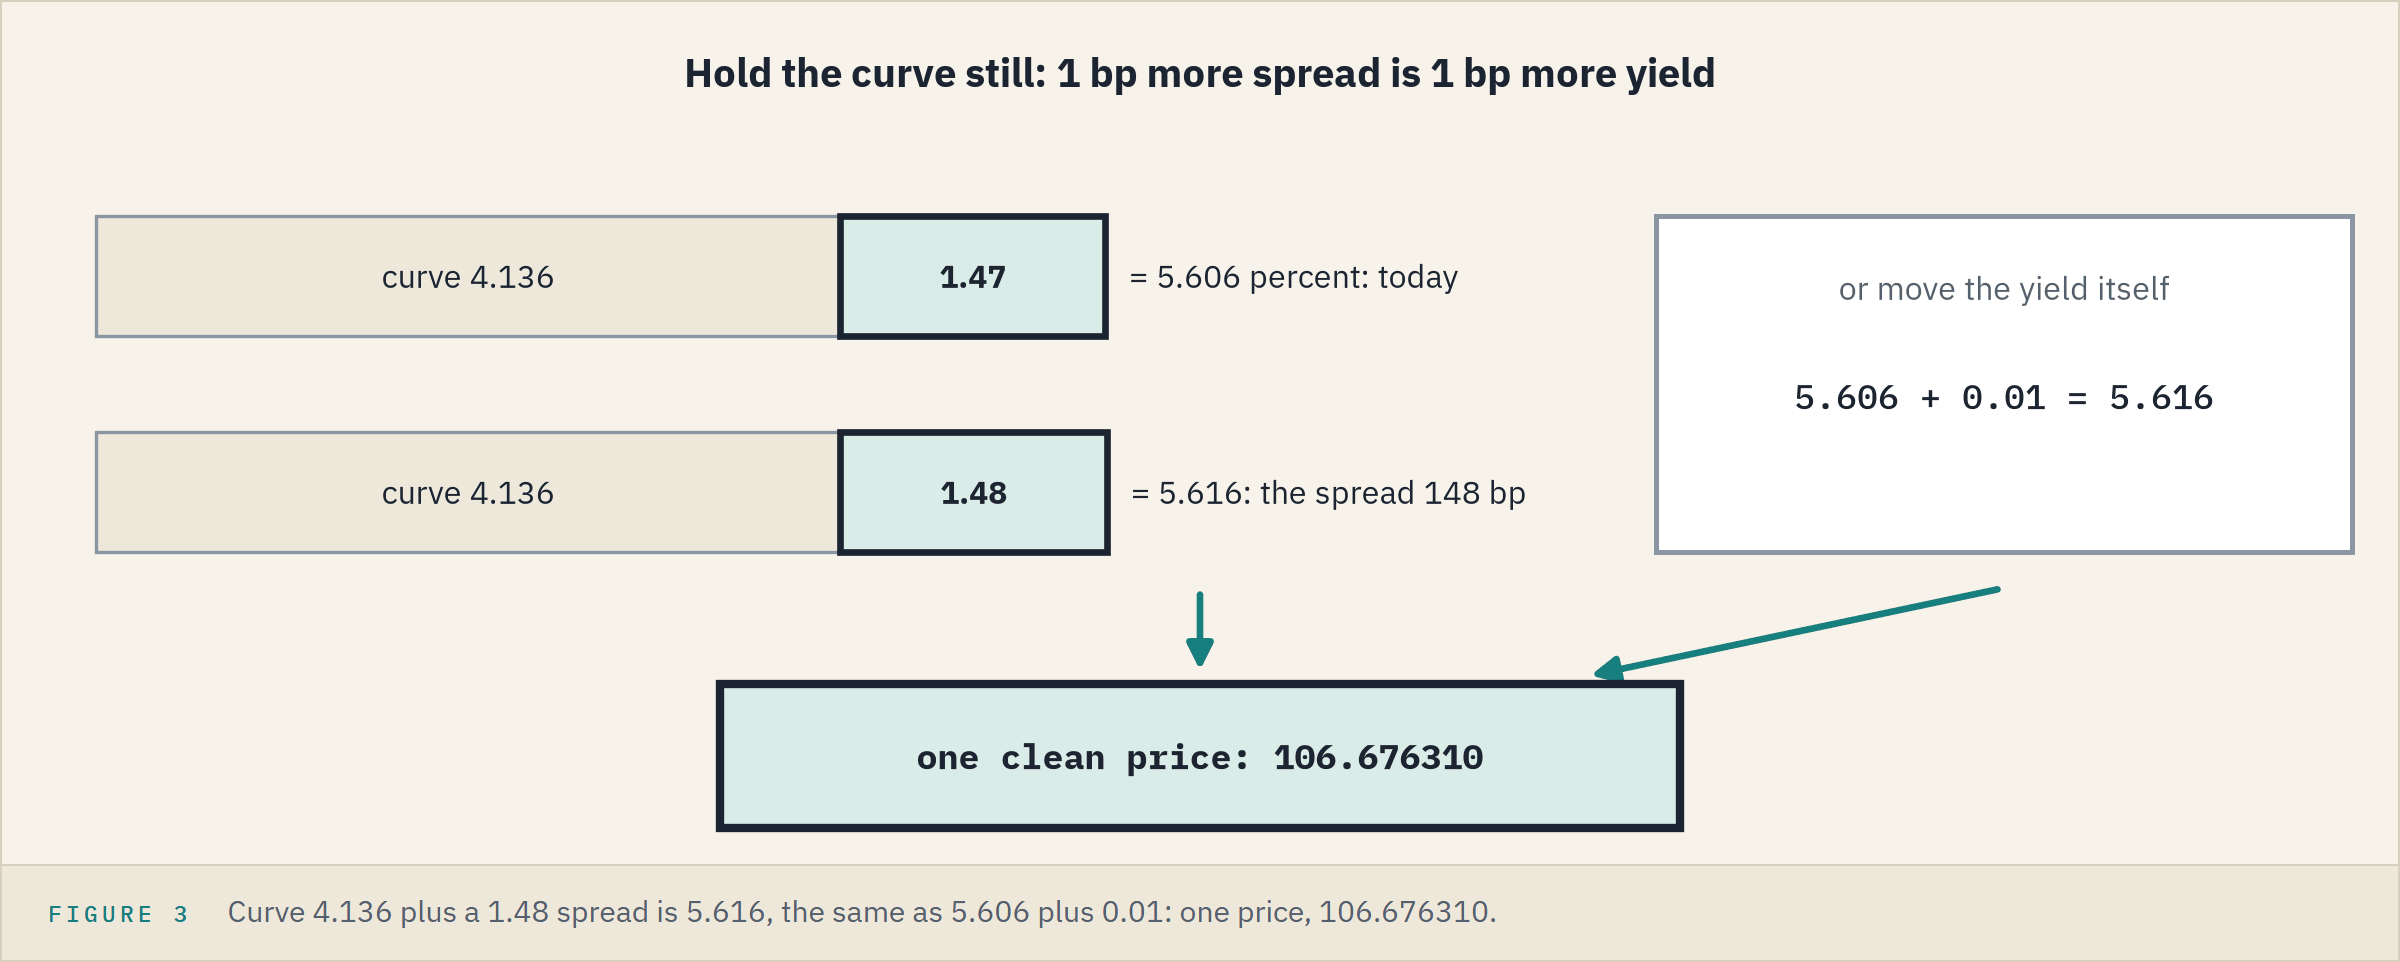

Notebook 12 found the file's rule: yield = curve yield + spread / 100.
Hold the curve, and 1 bp more spread is 1 bp more yield.

### Curve Plus Spread, Moved

Q. Rebuild Bezane's yield from the curve, then widen the spread instead of the yield.

In [8]:
import math

years = bondmath.years_to_maturity(settlement, maturity)
# notebook 12's curve formula at the bond's own years, rounded to 3 decimals
curve_pct = round(3.55 + 1.05 * (1 - math.exp(-years / 7)), 3)
print(f'{curve_pct} + {spread_bp} / 100 = {curve_pct + spread_bp / 100:.3f} percent')
# the spread 1 bp wider, the curve held still
price_wider = bondmath.price(settlement, maturity, coupon_pct, curve_pct + (spread_bp + 1) / 100)
print(f'spread 1 bp wider {price_wider:.12f}; yield 1 bp higher {price_up:.12f}')

4.136 + 147 / 100 = 5.606 percent
spread 1 bp wider 106.676309690525; yield 1 bp higher 106.676309690525


The same price to twelve decimals.

**Excel side by side.** The spread moved inside `PRICE`, beside 13.1's cells.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Curve plus spread, 1 bp wider (B11)</td><td align="left"><code>bondmath.price(settlement, maturity, coupon_pct, curve_pct + (spread_bp + 1) / 100)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,(4.136+(147+1)/100)/100,100,2,0)</code></td><td align="left">106.67630969052466</td></tr>
<tr><td align="left">Against the yield moved</td><td align="left"><code>price_wider - price_up</code></td><td align="left"><code>=B11-B3</code></td><td align="left">0</td></tr>
</table>
<br clear="left">

The same with `147-1` in B10 gives `=B10-B2` of 0.

**Predict 2**

Q. A spread move is a yield move, so spread duration should be notebook 09's modified duration. The bump measures it between two prices 2 bp apart. For Bezane, the two are:

A) equal in every digit: a spread move is exactly a yield move

B) equal to about six decimals: the price curve bends a little over 2 bp

C) different in the second decimal: the bump is in basis points

### Against Modified Duration

In [9]:
modified = bondmath.modified_duration(settlement, maturity, coupon_pct, yield_pct)
print(f'the bump:          {spread_duration_years:.9f} years')
print(f'modified duration: {modified:.9f} years')
print(f'difference:        {spread_duration_years - modified:.2e} years')

the bump:          4.626970799 years
modified duration: 4.626970521 years
difference:        2.78e-07 years


B: the bump sits 2.78e-07 years above modified duration.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Modified duration (B6)</td><td align="left"><code>bondmath.modified_duration(settlement, maturity, coupon_pct, yield_pct)</code></td><td align="left"><code>=MDURATION(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100,2,0)</code></td><td align="left">4.626970520675595</td></tr>
<tr><td align="left">The bump less it</td><td align="left"><code>spread_duration_years - modified</code></td><td align="left"><code>=B5-B6</code></td><td align="left">2.784743857731087e-07</td></tr>
</table>
<br clear="left">

**Not a copy error: hold the curve, and a spread move is a yield move, so spread duration is modified duration, to 2.78e-07 years on Bezane.**

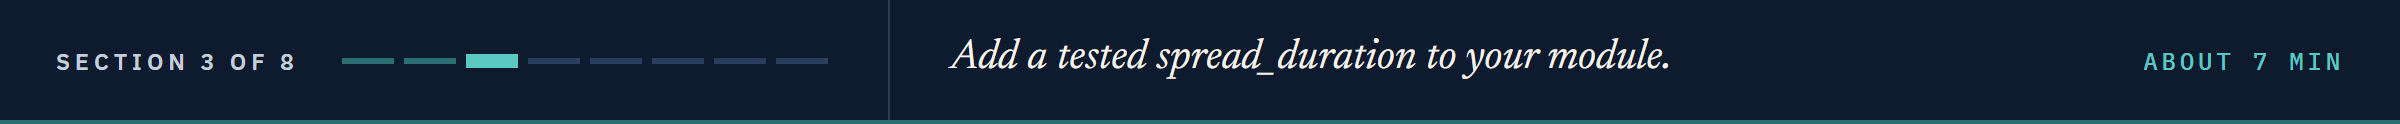

## 13.3 `spread_duration`, Docstring First

### Append It

Q. Add `spread_duration` to the module. Read the docstring before you run the cell.

In [10]:
%%writefile -a bondmath.py


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price

Appending to bondmath.py


`bump_pct` moves `yield_pct`, which is in percent; `bump_decimal` divides the slope.
Two names for one bump keep the two units apart.
A bump of zero would divide by zero, so the function refuses it.

**Excel side by side.** The docstring's formula fits in one cell, tested: `=(PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100-0.0001,100,2,0)-PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100+0.0001,100,2,0))/(2*0.0001)/(PRICE(DATE(2026,9,30),DATE(2032,6,18),7/100,5.606/100,100,2,0)+100*7/100/2*COUPDAYBS(DATE(2026,9,30),DATE(2032,6,18),2,0)/COUPDAYS(DATE(2026,9,30),DATE(2032,6,18),2,0))` returns 4.626970799149981, as B5 does.

### Bezane Against Excel

In [11]:
import importlib

importlib.reload(bondmath)
bezane_sd = bondmath.spread_duration(settlement, maturity, coupon_pct, yield_pct)
# Excel's B5, from the course's Excel run
excel_b5 = 4.626970799149981
print(f'bondmath {bezane_sd:.12f}, Excel {excel_b5:.12f}')
# :.1e writes a number in scientific notation: 1.3e-12 is 0.0000000000013
print(f'gap {abs(bezane_sd - excel_b5):.1e} years')

bondmath 4.626970799151, Excel 4.626970799150
gap 1.3e-12 years


### Excel's Spread Duration for Every Holdings Bond

The reference file holds Excel's two bumped prices for each of the 200, `price_down_1bp` and `price_up_1bp`, which notebook 09's bump test read.

In [12]:
reference = pd.read_csv('bondmath_excel_reference.csv')
# the 200 holdings rows, labelled by CUSIP
excel = reference[reference['group'] == 'holdings'].set_index('case_id')
excel_sd = ((excel['price_down_1bp'] - excel['price_up_1bp']) / (2 * 0.0001)
            / (excel['price'] + excel['accrued']))
print(f"{len(excel_sd)} bonds; Bezane {excel_sd.loc['99080CAE8']:.12f} years")

200 bonds; Bezane 4.626970799150 years


### All 200 Against Excel

In [13]:
# each bond's four inputs in one tuple; * hands them over one by one, as in notebook 08
bonds = list(zip(holdings['as_of_date'], holdings['maturity'], holdings['coupon'],
                 holdings['yield_pct']))
holdings['spread_duration_bm'] = [bondmath.spread_duration(*bond) for bond in bonds]
# .map looks each CUSIP up in Excel's column, as it would in a dict
gap = (holdings['spread_duration_bm'] - holdings['cusip'].map(excel_sd)).abs()
assert gap.max() < 1e-6, 'a bond differs from Excel'
print(f'largest gap to Excel over 200 bonds: {gap.max():.1e} years')

largest gap to Excel over 200 bonds: 3.0e-11 years


### All 200 Against Modified Duration

In [14]:
holdings['modified_bm'] = [bondmath.modified_duration(*bond) for bond in bonds]
holdings['sd_minus_md'] = holdings['spread_duration_bm'] - holdings['modified_bm']
print(f"{holdings['sd_minus_md'].min():.2e} to {holdings['sd_minus_md'].max():.2e} years")
furthest = holdings['sd_minus_md'].idxmax()
holdings.loc[furthest, ['cusip', 'issuer', 'maturity', 'modified_bm']]

4.36e-09 to 1.61e-05 years


cusip                    99053BAB9
issuer         Sylvellix Logistics
maturity                2055-09-03
modified_bm              16.042473
Name: 150, dtype: object

Every bump sits above modified duration, by less than 0.00002 years.
The furthest is Sylvellix Logistics, maturing in 2055.
The bump measures a chord between two points 2 bp apart.
The price curve bends (notebook 10's convexity), and bends more on the tighter side, so the chord is a hair steeper than the curve at its middle.

**Predict 3**

Q. Measure Sylvellix with bumps of 1, 5, 25 and 100 bp. Five times the bump does what to its gap above modified duration?

A) about the same: the gap is rounding

B) about five times: the gap grows with the bump

C) about twenty-five times: the gap grows with the square of the bump

### The Gap by Size of Bump

In [15]:
sylvellix = bonds[furthest]
modified_syl = bondmath.modified_duration(*sylvellix)
bump_table = pd.DataFrame({'bump_bp': [1, 5, 25, 100]})
bump_table['gap_years'] = [bondmath.spread_duration(*sylvellix, bump_bp=b) - modified_syl
                           for b in bump_table['bump_bp']]
bump_table.style.format({'gap_years': '{:.1e}'}).hide(axis='index')

bump_bp,gap_years
1,1.6e-05
5,4.0e-04
25,1.0e-02
100,1.6e-01


### Draw It

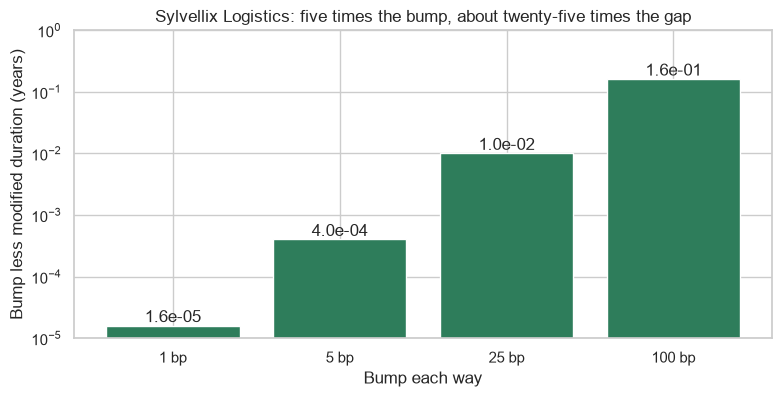

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar([f'{b} bp' for b in bump_table['bump_bp']], bump_table['gap_years'])
# the gaps span four powers of ten, so the axis is logarithmic
ax.set_yscale('log')
ax.set_ylim(1e-5, 1)
ax.bar_label(bars, fmt='%.1e')
ax.set_title('Sylvellix Logistics: five times the bump, about twenty-five times the gap')
ax.set_xlabel('Bump each way')
ax.set_ylabel('Bump less modified duration (years)')
plt.show()

C: five times the bump, about twenty-five times the gap.
At 100 bp the bump is off by 0.16 years; at 1 bp by 0.000016.
**1 bp is the right size.**

One case differs: a bond in its final coupon period, which Excel prices with simple interest (notebook 08).
On the reference row `edge_final_period` the bump gives 0.366748 years and `MDURATION` 0.364078.
No holdings bond is in its final period, and the test leaves those rows out.

### The First Test

The test keeps the rows outside the final period with a comprehension's `if`, as Course 1 filtered lists.
Its tolerance, 5e-5 years, is the course's: above the 1.6e-05 measured, far below anything a desk reads.

In [17]:
%%writefile -a test_bondmath.py


def test_spread_duration_equals_modified_duration():
    # final-period rows are left out: simple interest, so the bump is not the same measure
    rows = [row for row in REFERENCE if row["coupnum"] != "1"]
    for row in rows:
        # for a bullet priced at curve plus spread, a spread move is a yield move; the 1 bp central
        # difference sits above the exact slope by up to 1.6e-5 years on a 30-year bond
        result = bondmath.spread_duration(*bond_inputs(row))
        assert result == pytest.approx(bondmath.modified_duration(*bond_inputs(row)), abs=5e-5), row["case_id"]

Appending to test_bondmath.py


In [18]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................                                     [100%]
36 passed in 0.50s



**`spread_duration` matches Excel's bumped `PRICE` on all 200 bonds and sits within 0.00002 years of modified duration.**

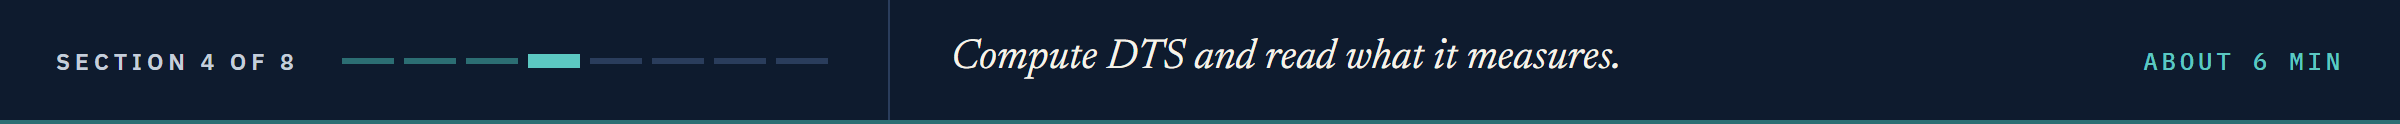

## 13.4 DTS: Spread Duration Times Spread

Spread duration says what a move of so many bp does to the price.
Spreads do not all move by the same number of bp.
**DTS**, duration times spread, measures a move stated as a share of the spread: spread duration in years times the spread in bp.
It is a published measure: Ben Dor, Dynkin, Hyman, Houweling, van Leeuwen and Penninga, "DTS (Duration Times Spread)", *Journal of Portfolio Management*, Winter 2007 ([CFA Institute's summary](https://rpc.cfainstitute.org/-/media/documents/article/cfa-digest/2007/dig-v37-n3-4779-pdf.pdf)).
On credit index data from 1989 to 2005 they found that bonds at wider spreads moved more in bp, roughly in proportion to their spread.
If a spread widens by 10 percent of itself, the move is 0.10 x spread bp, so the price changes by about -DTS x 0.10 / 100 percent.

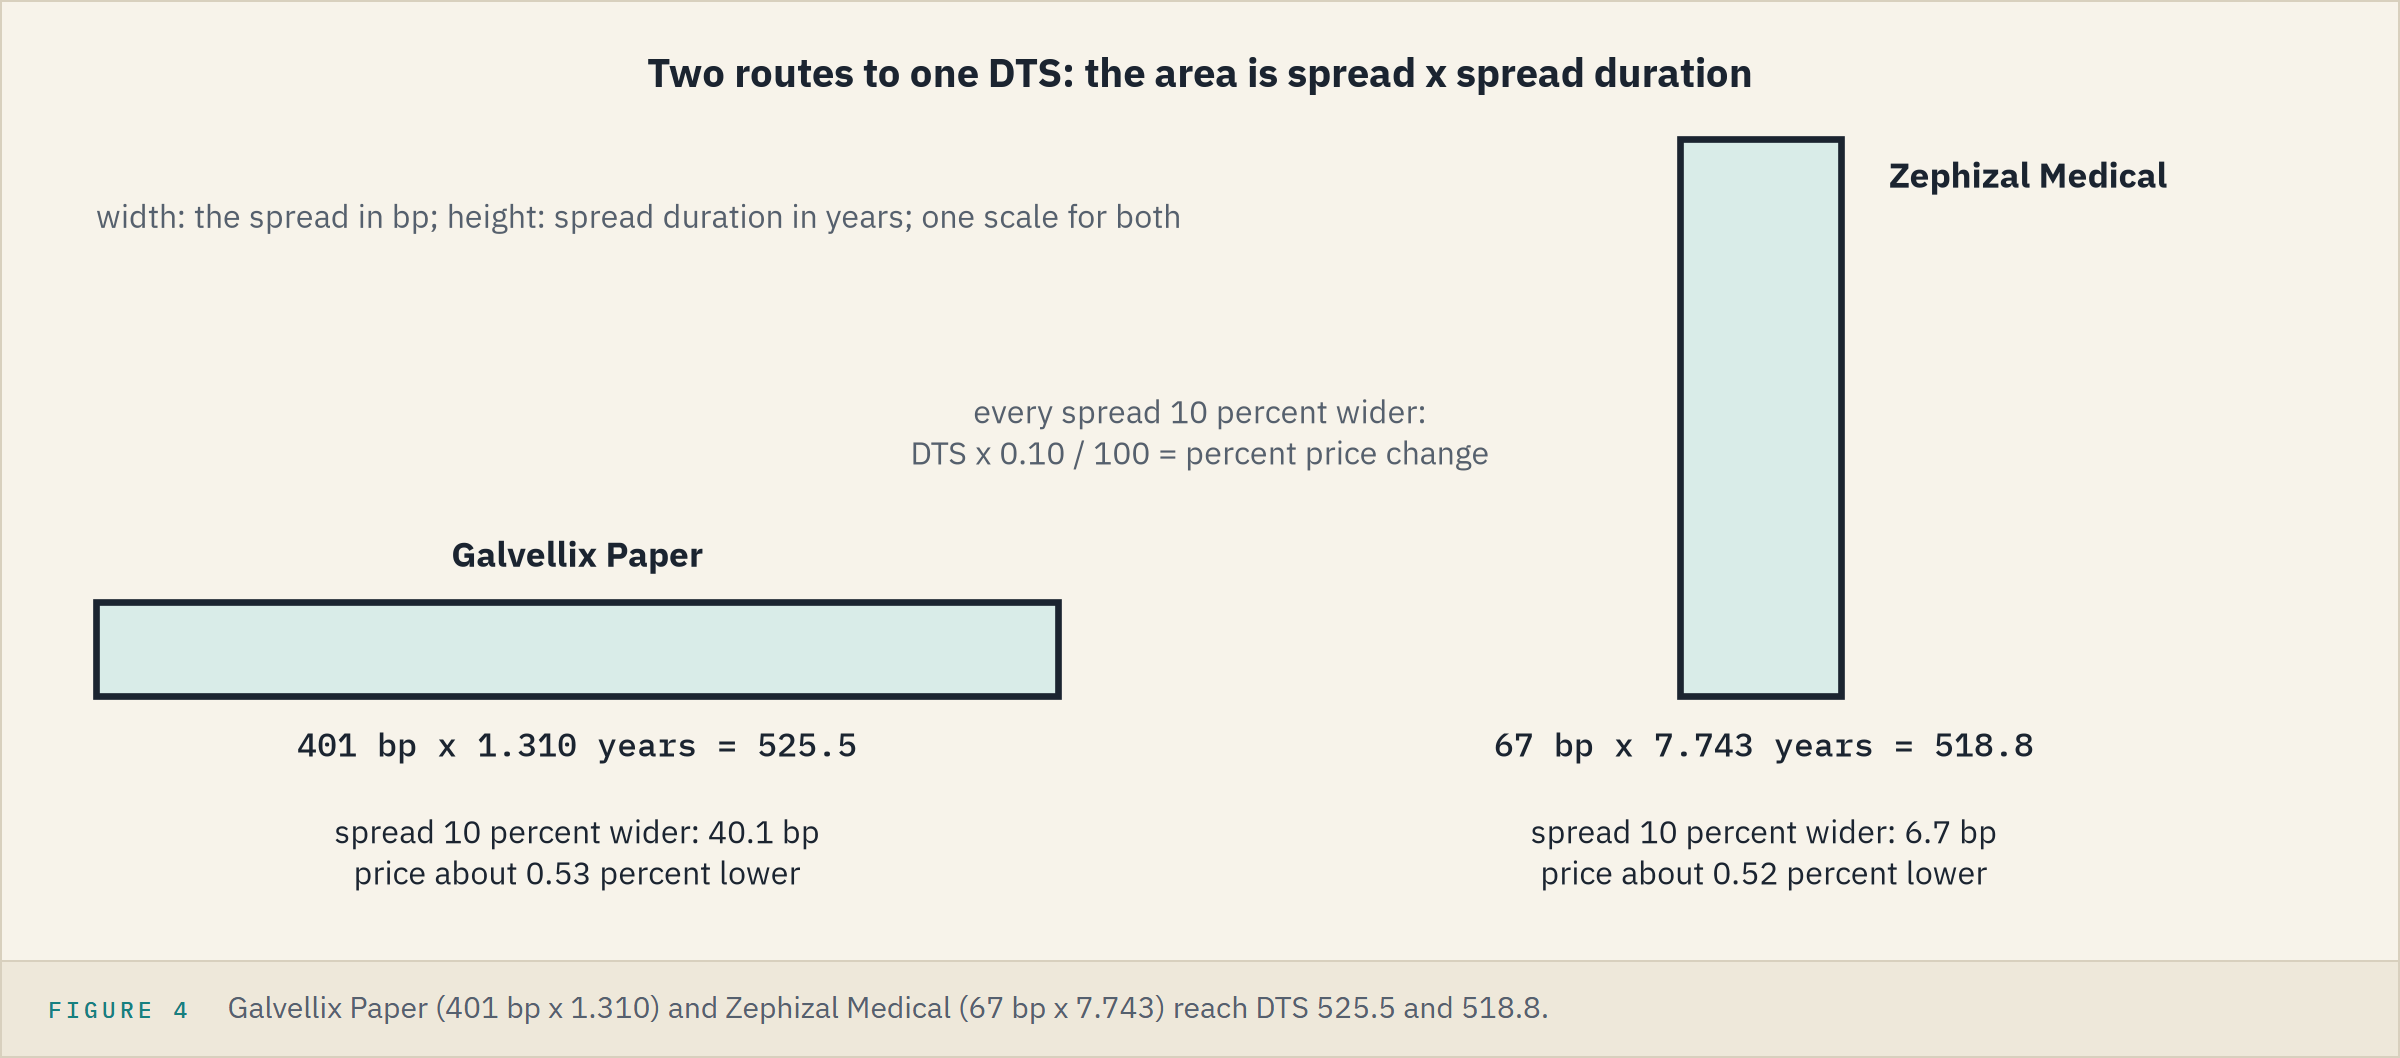

Two bonds of the book reach almost the same DTS by opposite routes.
With every spread 10 percent wider, both lose about half a percent.

**Predict 4**

Q. Bezane's spread doubles, 147 bp wider, and DTS says the price falls 6.80 percent. A full reprice says:

A) a smaller fall, by a few tenths of a percent

B) the same fall, to the hundredth

C) a larger fall, by a few tenths of a percent

### Bezane's DTS, and Two Widenings

In [19]:
dts_bezane = bezane_sd * spread_bp
print(f'DTS {bezane_sd:.6f} years x {spread_bp} bp = {dts_bezane:.4f} years x bp')
for share in [0.10, 1.00]:
    widening_bp = share * spread_bp
    new_yield = yield_pct + widening_bp / 100
    dirty_after = bondmath.dirty_price(settlement, maturity, coupon_pct, new_yield)
    print(f'{widening_bp:.1f} bp wider: DTS says {-dts_bezane * share / 100:.4f} percent, '
          f'a full reprice {(dirty_after - dirty) / dirty * 100:.4f}')

DTS 4.626971 years x 147 bp = 680.1647 years x bp
14.7 bp wider: DTS says -0.6802 percent, a full reprice -0.6773
147.0 bp wider: DTS says -6.8016 percent, a full reprice -6.5255


A: the full reprice falls 6.5255 percent, 0.28 less than DTS says.
DTS is a straight line, and convexity bends the price away from it as the move grows (notebook 10).
At 10 percent wider the two are 0.003 apart.
This is arithmetic on one invented bond, not a forecast.

### The Pair From the Picture

In [20]:
pair = holdings[holdings['cusip'].isin(['99088KAA0', '99062KAE2'])]
pair[['cusip', 'issuer', 'oas', 'spread_duration_bm']].round(3)

,cusip,issuer,oas,spread_duration_bm
71,99088KAA0,Galvellix Paper,401,1.310
196,99062KAE2,Zephizal Medical,67,7.743


### Every Bond, With Lines of Equal DTS

A line of equal DTS is spread duration = DTS / spread.
`ax.set_xscale('log')`, as in notebook 01, spaces the spread axis by multiples: 50 to 100 bp is as wide as 500 to 1000.

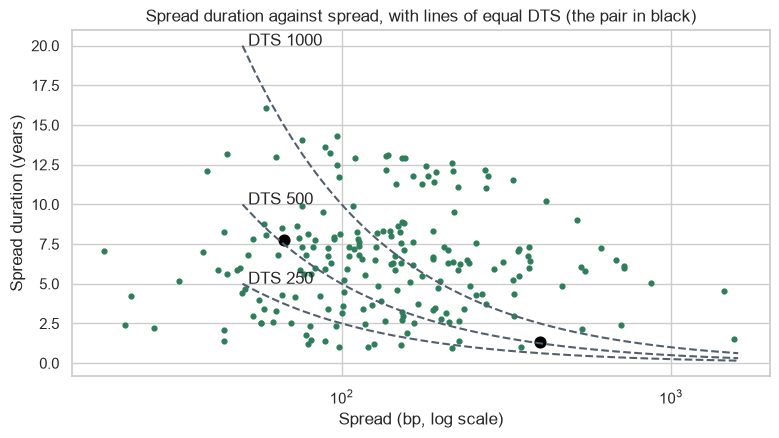

In [21]:
spreads = np.linspace(50, 1600, 300)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(holdings['oas'], holdings['spread_duration_bm'], s=12)
ax.scatter(pair['oas'], pair['spread_duration_bm'], s=60, color='black')
for level in [250, 500, 1000]:
    ax.plot(spreads, level / spreads, color='#52606D', linestyle='--')
    ax.text(52, level / 50, f'DTS {level}')
ax.set_xscale('log')
ax.set_title('Spread duration against spread, with lines of equal DTS (the pair in black)')
ax.set_xlabel('Spread (bp, log scale)')
ax.set_ylabel('Spread duration (years)')
plt.show()

A bond on a dashed line has that DTS, however it got there: short and wide, or long and tight.

### Append `dts`

In [22]:
%%writefile -a bondmath.py


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp

Appending to bondmath.py


One line, on purpose: the docstring carries the unit, years times bp, so the number is never read as a percent or a dollar amount.

### Bezane's DTS From the Module

In [23]:
importlib.reload(bondmath)
print(f"bondmath.dts {bondmath.dts(bezane_sd, spread_bp):.4f}; the file's dts {bezane['dts']}")

bondmath.dts 680.1647; the file's dts 680.2


The file rounds its `dts` to one decimal.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">DTS (B7)</td><td align="left"><code>bondmath.dts(bezane_sd, spread_bp)</code></td><td align="left"><code>=B5*147</code></td><td align="left">680.1647074750472</td></tr>
</table>
<br clear="left">

**Two bonds with the same DTS lose about the same share of value when every spread moves by the same share, whatever their duration and spread.**

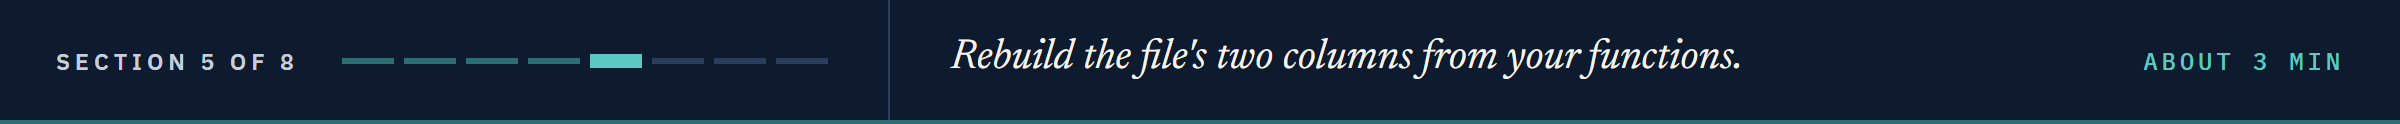

## 13.5 The File's Two Columns, Rebuilt

The file's generator, `tools/make_holdings.py`, wrote `spread_duration` as its `duration`, modified duration rounded to 3 decimals, for 13.2's reason.
Its `dts` is that rounded number times `oas`, rounded to 1 decimal.

### `spread_duration` Against the File

In [24]:
gap_sd = (holdings['spread_duration_bm'] - holdings['spread_duration']).abs()
# rounding to 3 decimals moves a number by up to 0.0005
assert (gap_sd <= 0.0005 + 1e-9).all(), "a bond's spread duration differs from the file"
print(f'largest gap {gap_sd.max():.9f} years')
holdings.loc[gap_sd.idxmax(), ['cusip', 'spread_duration_bm', 'spread_duration']]

largest gap 0.000498707 years


cusip                 99010KAH8
spread_duration_bm     5.950499
spread_duration            5.95
Name: 154, dtype: object

5.950498707 is stored as 5.95: the rounding, plus a few millionths from the bump.

### `dts` From the File's Own Columns

`bondmath.dts` takes whole columns too: `*` on two columns multiplies row by row.

In [25]:
from_file = (bondmath.dts(holdings['spread_duration'], holdings['oas']) - holdings['dts']).abs()
# the file rounds dts to 1 decimal: up to 0.05, plus a trace of floating point
assert (from_file <= 0.05 + 1e-9).all(), "a row's dts differs from the file"
print(f'largest gap {from_file.max():.13f}')

largest gap 0.0500000000002


### `dts` From the Bond Math

In [26]:
holdings['dts_bm'] = bondmath.dts(holdings['spread_duration_bm'], holdings['oas'])
from_math = (holdings['dts_bm'] - holdings['dts']).abs()
print(f'largest gap {from_math.max():.4f}; {(from_math > 0.05).sum()} of 200 bonds above 0.05')
holdings.loc[from_math.idxmax(), ['cusip', 'oas', 'spread_duration']]

largest gap 0.3999; 82 of 200 bonds above 0.05


cusip              99038MAE9
oas                      871
spread_duration        5.058
Name: 132, dtype: object

A spread of 871 bp multiplies the file's 3-decimal rounding of spread duration, so no tolerance is claimed for this route.

### The Second Test

Five rows typed in, with the same five CUSIPs as notebook 12's test.

In [27]:
%%writefile -a test_bondmath.py


def test_dts_reproduces_file_rows():
    # five rows of holdings.csv: cusip, spread_duration, oas, dts (the file rounds dts to 1 decimal)
    rows = [
        ("99080CAE8", 4.627, 147, 680.2),
        ("99049XAE2", 2.165, 535, 1158.3),
        ("99039NAC0", 3.25, 153, 497.2),
        ("99039NAG1", 12.113, 218, 2640.6),
        ("99034IAD4", 7.338, 127, 931.9),
    ]
    for cusip, spread_duration_years, spread_bp, file_dts in rows:
        assert bondmath.dts(spread_duration_years, spread_bp) == pytest.approx(file_dts, abs=0.05 + 1e-9), cusip

Appending to test_bondmath.py


In [28]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................................                                    [100%]
37 passed in 0.50s



**Both columns rebuilt: what differs is the file's rounding, never the math.**

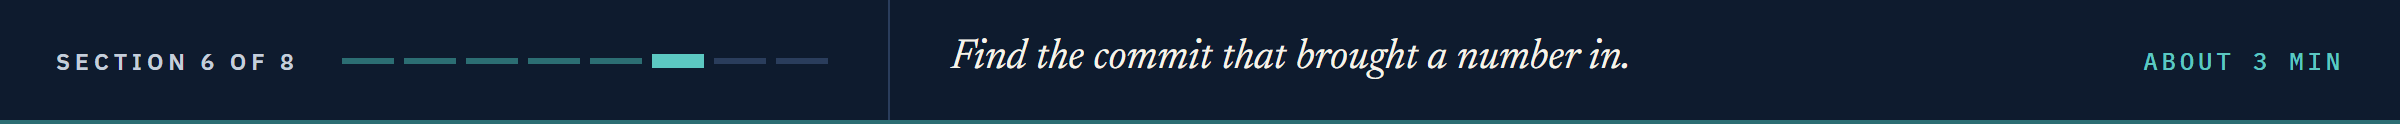

## 13.6 When Did 10000 Arrive?

### Read the Change, Commit It

In [29]:
!git -C "{work}" diff --stat
subject = 'Notebook 13: spread_duration and dts'
body = 'Spread duration and DTS feed the risk report of notebook 14'
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"

 bondmath.py      | 34 ++++++++++++++++++++++++++++++++++
 test_bondmath.py | 23 +++++++++++++++++++++++
 2 files changed, 57 insertions(+)


`bump_decimal` divides by 10000, and so did an earlier day.
`git log -S "10000"` lists the commits that changed how many times the text `10000` appears in the files.
Git calls it the pickaxe.

### The Pickaxe

In [30]:
!git -C "{work}" log -S "10000" --oneline

e42ff20 Notebook 13: spread_duration and dts
5fcb7c6 Notebook 09: macaulay_duration, modified_duration, and dv01


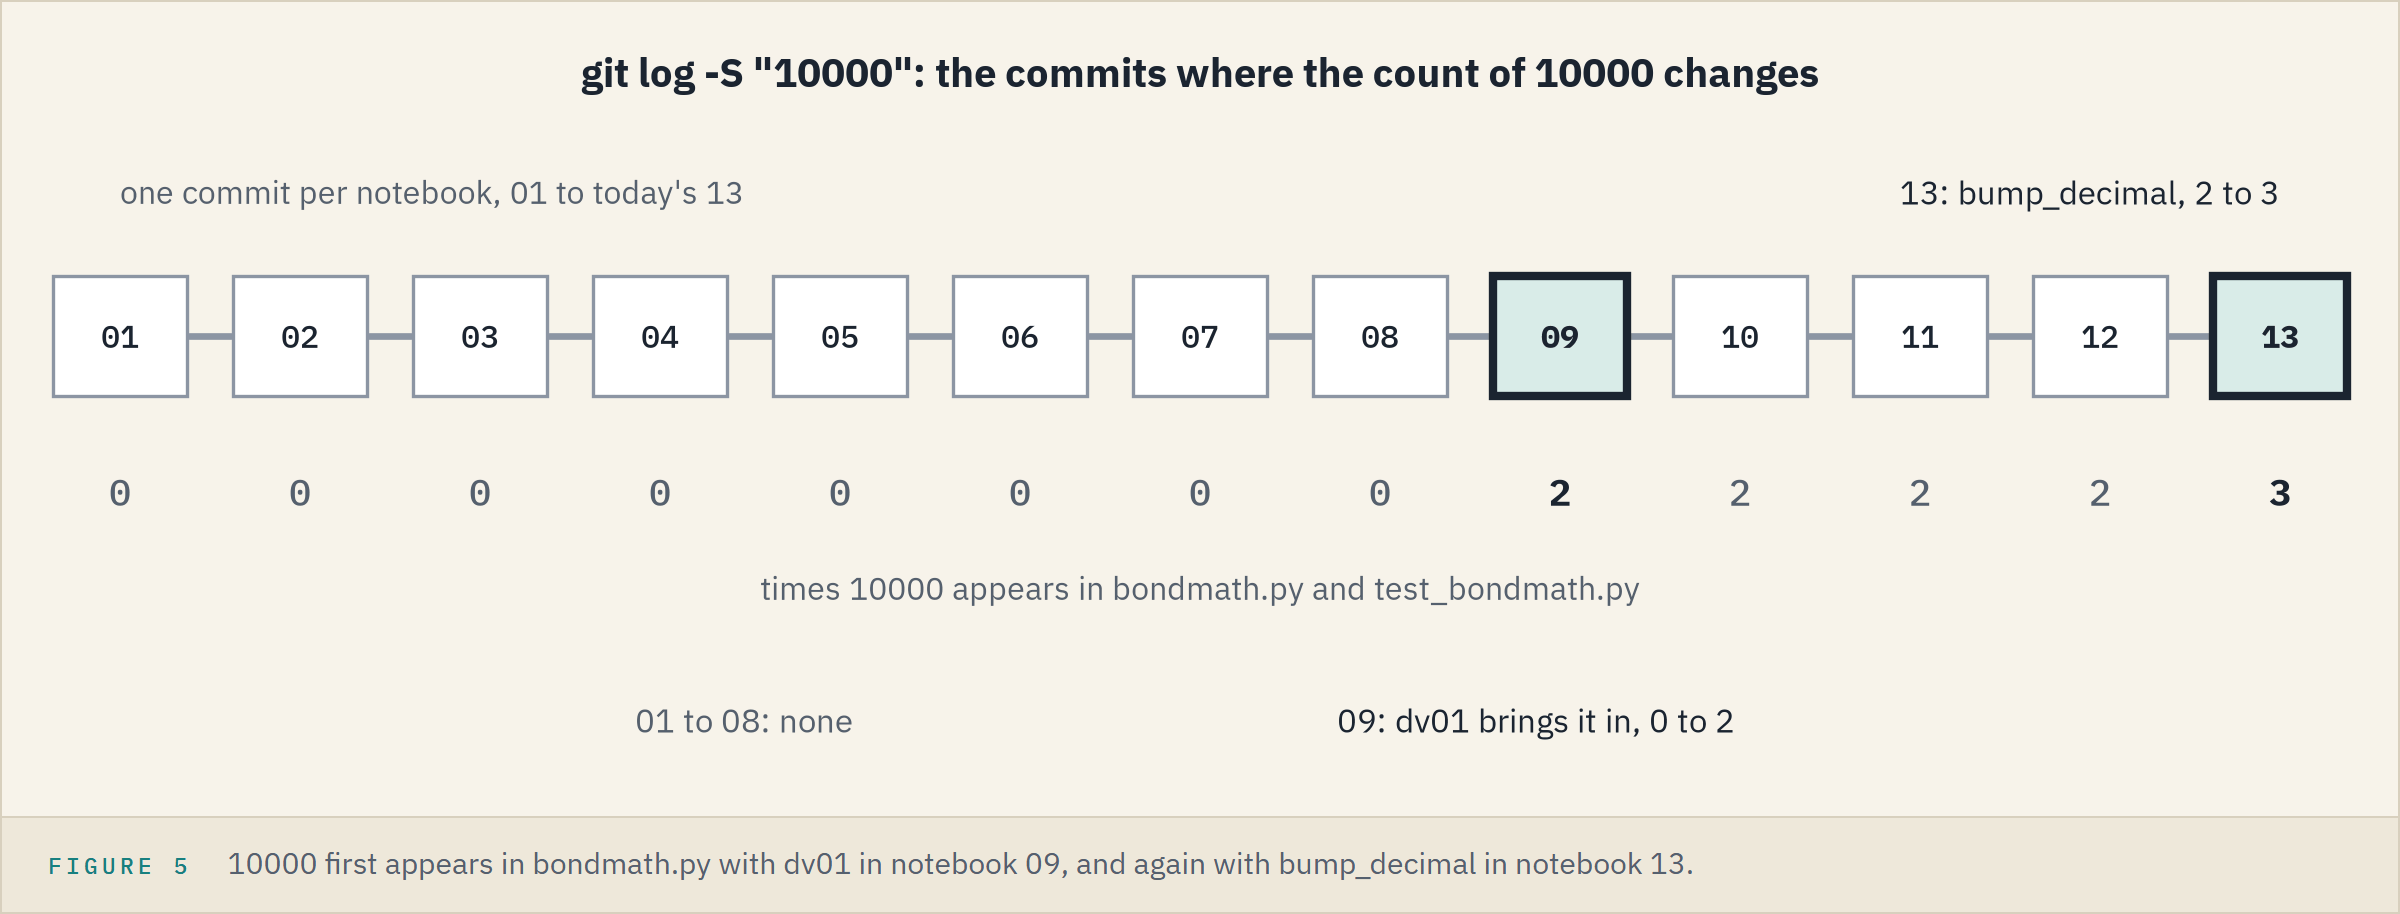

Two commits, newest first: the two where the count changes.
The oldest is where 10000 came in: notebook 09's `dv01`, whose docstring checks it as `MDURATION(...)*(PRICE(...)+accrued)/10000`.
The search reads the changes, not the messages: neither subject mentions 10000.

### In the Test File Only

In [31]:
!git -C "{work}" log -S "10000" --oneline -- test_bondmath.py

5fcb7c6 Notebook 09: macaulay_duration, modified_duration, and dv01


Only notebook 09: its DV01 test's comment holds the formula, and today's tests do not use the number.

**`git log -S` finds the commit that brought a number in: 10000 arrived with `dv01` in notebook 09.**

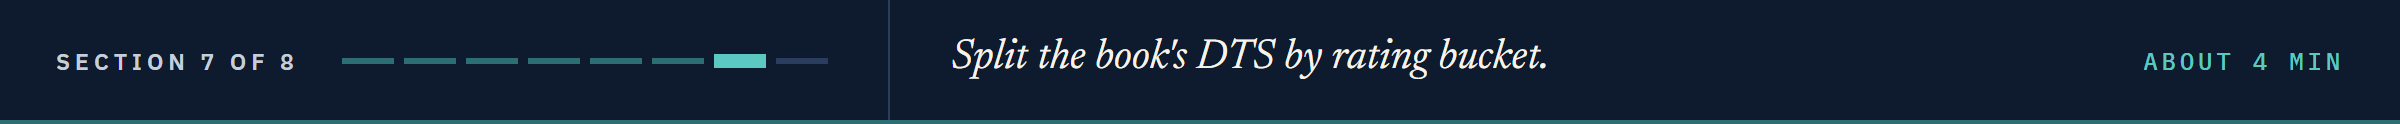

## 13.7 The Book's DTS by Rating Bucket

A bond's weight is its share of the book's market value; its contribution is the weight, as a fraction, times its DTS.
The contributions add up to the book's DTS, as the Course 1 project's picture of three invented bonds showed.
This time every DTS is your own.

### The Book's DTS From Your Own Functions

In [32]:
total_value = holdings['market_value'].sum()
holdings['weight_pct'] = holdings['market_value'] / total_value * 100
# weight_pct is in percent: divide by 100 for the fraction
holdings['dts_contribution'] = holdings['weight_pct'] / 100 * holdings['dts_bm']
book_dts = holdings['dts_contribution'].sum()
print(f'book DTS, the contributions added up: {book_dts:.6f} years x bp')

book DTS, the contributions added up: 1064.110539 years x bp


In [33]:
weighted = (holdings['market_value'] * holdings['dts_bm']).sum() / total_value
from_column = (holdings['weight_pct'] / 100 * holdings['dts']).sum()
print(f'book DTS, the weighted average: {weighted:.6f} years x bp')
print(f"book DTS from the file's dts column: {from_column:.6f} years x bp")

book DTS, the weighted average: 1064.110539 years x bp
book DTS from the file's dts column: 1064.113487 years x bp


Your own book DTS, two ways, to the sixth decimal.
The file's rounded column moves it by 0.0029.

**Excel side by side.** The book in a sheet, rows 2 to 201: rating bucket in B, `oas` in F, market value in G, the three `PRICE` cells in H to J, accrued in K, settlement in Q1.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Spread duration (L)</td><td align="left"><code>bondmath.spread_duration(*bond)</code></td><td align="left"><code>=(I2-J2)/(2*0.0001)/(H2+K2)</code></td><td align="left">filled down</td></tr>
<tr><td align="left">DTS (M)</td><td align="left"><code>bondmath.dts(...)</code></td><td align="left"><code>=L2*F2</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Weight (N)</td><td align="left"><code>market_value / total_value * 100</code></td><td align="left"><code>=G2/SUM($G$2:$G$201)*100</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Contribution (O)</td><td align="left"><code>weight_pct / 100 * dts_bm</code></td><td align="left"><code>=N2/100*M2</code></td><td align="left">filled down</td></tr>
<tr><td align="left">Book DTS</td><td align="left"><code>holdings['dts_contribution'].sum()</code></td><td align="left"><code>=SUM(O2:O201)</code></td><td align="left">1064.1105392423183</td></tr>
<tr><td align="left">Book DTS, one cell</td><td align="left">the weighted average</td><td align="left"><code>=SUMPRODUCT(G2:G201,M2:M201)/SUM(G2:G201)</code></td><td align="left">1064.1105392423187</td></tr>
</table>
<br clear="left">

### By Bucket, in Credit Order

In [34]:
ratings = pd.read_csv('ratings.csv')
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
book = holdings.merge(ratings[['rating', 'bucket', 'grade']], on='rating', how='left')
by_bucket = book.groupby('bucket')[['weight_pct', 'dts_contribution']].sum().loc[bucket_order]
by_bucket['share_of_dts_pct'] = by_bucket['dts_contribution'] / book_dts * 100
by_bucket.round(2)

,weight_pct,dts_contribution,share_of_dts_pct
bucket,,,
AAA,1.67,1.95,0.18
AA,2.66,4.00,0.38
A,30.26,153.45,14.42
BBB,30.80,297.24,27.93
BB,23.18,292.47,27.49
B,8.88,230.04,21.62
CCC,2.56,84.95,7.98


**Excel side by side.** `=SUMIFS(O2:O201,B2:B201,"BBB")` returns 297.2402393040499, BBB's row; every bucket's `SUMIFS` equals the table to 1e-9.

### Dollars Against Spread Risk

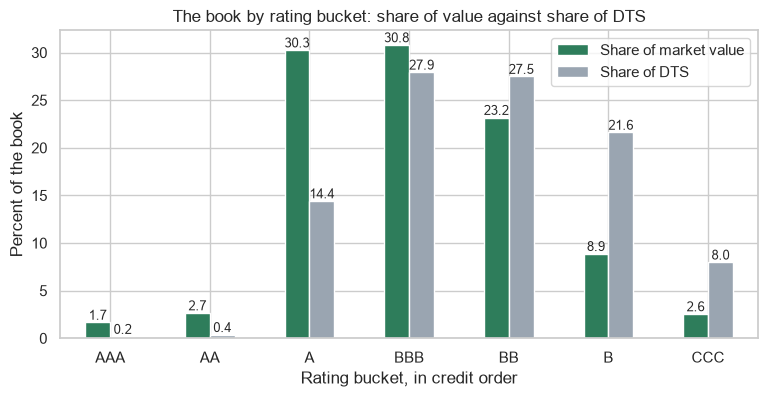

In [35]:
shares = by_bucket[['weight_pct', 'share_of_dts_pct']].rename(
    columns={'weight_pct': 'Share of market value', 'share_of_dts_pct': 'Share of DTS'})
fig, ax = plt.subplots(figsize=(9, 4))
# ax=ax draws pandas' bars on these axes, as seaborn's ax= does
shares.plot.bar(ax=ax, rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', fontsize=9)
ax.set_title('The book by rating bucket: share of value against share of DTS')
ax.set_xlabel('Rating bucket, in credit order')
ax.set_ylabel('Percent of the book')
plt.show()

From AAA to BBB each bucket's share of value is larger than its share of DTS; from BB down, the DTS share is larger.

### By Grade

In [36]:
by_grade = book.groupby('grade')[['weight_pct', 'dts_contribution']].sum()
by_grade['share_of_dts_pct'] = by_grade['dts_contribution'] / book_dts * 100
by_grade.round(1)

,weight_pct,dts_contribution,share_of_dts_pct
grade,,,
High Yield,34.6,607.5,57.1
Investment Grade,65.4,456.6,42.9


A description of where the spread risk of this invented book sits, nothing more.

**High Yield is 34.6 percent of the book's value and 57.1 percent of its DTS: the dollars and the spread risk sit in different buckets.**

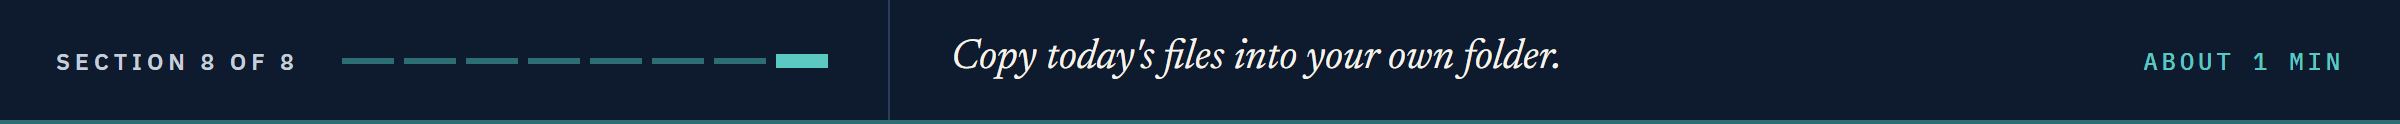

## Bring It Home

Copy today's two files into your own `my_bondmath` folder, then test and commit there.
The copy replaces your files: anything of your own must be in the work folder first.
In PowerShell, with the course's `.venv` active, and your eight characters from the setup cell in place of `k4w7q2xr`:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_13_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py", "$work\.gitignore" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git commit -m "Notebook 13: spread_duration and dts" -m "Spread duration and DTS feed the risk report of notebook 14"
git log -S "10000" --oneline
git log -S "10000" --oneline -- test_bondmath.py
```

Your list may be longer: an exercise of your own that used 10000 is listed too.
In Colab, download the two files from the work folder in the file browser.
The work folder stays in your temp folder.

## You Can Now

By the end of this notebook, you can:

* Measure spread duration by moving the spread 1 bp each way and repricing, with `spread_duration` or three `PRICE` cells.
* Say why, for a bond priced at the curve plus a spread, spread duration is modified duration, and why the bump sits a hair above it.
* Compute DTS with `dts` and say what it measures: the price change when a spread moves by a share of itself.
* Rebuild the file's `spread_duration` and `dts` columns, and name the rounding that separates them.
* Add up the book's DTS by bond and by rating bucket, with pandas or with `SUMPRODUCT` and `SUMIFS`.
* Find the commit that brought a number in, with `git log -S`.

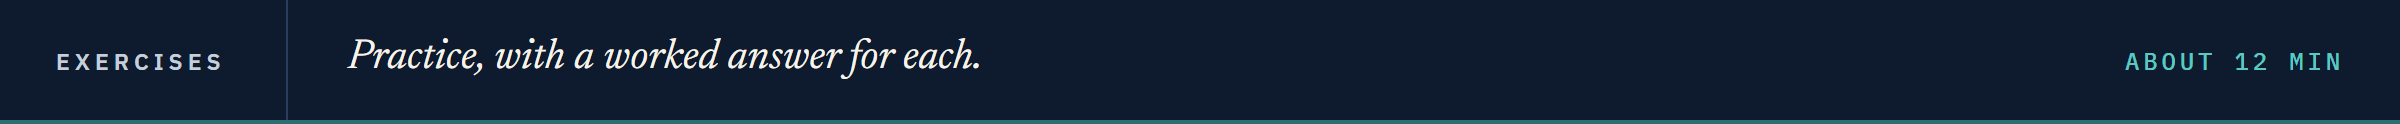

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use notebook 12's twenty bonds from `benchmark.csv`, the ones the book does not hold.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: `check`, and the twenty bonds.

In [37]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [38]:
# notebook 12's twenty: every 30th benchmark bond the book does not hold
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
twenty = not_held.iloc[::30].head(20).reset_index(drop=True)
twenty['as_of_date'] = pd.to_datetime(twenty['as_of_date']).dt.date
twenty['maturity'] = pd.to_datetime(twenty['maturity']).dt.date
twenty[['cusip', 'issuer', 'rating', 'oas', 'spread_duration', 'dts']].head()

,cusip,issuer,rating,oas,spread_duration,dts
0,99001BAB2,Quorvane Energy,BBB,122,6.834,833.7
1,99008IAD6,Osmere Chemicals,BBB-,111,4.903,544.2
2,99016QAG1,Corvolvey Systems,BB+,128,1.735,222.1
3,99025ZAD7,Kezazor Logistics,A,71,1.399,99.3
4,99032GAB4,Queloquil Health,BBB-,175,6.359,1112.8


### Exercise 1

Q. Add a column `sd` to `twenty` with `bondmath.spread_duration`, and `assert` that every one is within 0.0005 + 1e-9 of the file's `spread_duration`. Store the first bond's `sd` in `ex1_first` and the largest gap to the file in `ex1_largest_gap`.

In [39]:
ex1_first = ...
ex1_largest_gap = ...
check('Exercise 1 first spread duration', ex1_first, 6.833695612710124)
check('Exercise 1 largest gap', ex1_largest_gap, 0.0004981682148255118)

Exercise 1 first spread duration: not attempted yet
Exercise 1 largest gap: not attempted yet


### Exercise 2

Q. Add `dts_bm` to `twenty` with `bondmath.dts` from your `sd` and `oas`. Store the largest in `ex2_largest_dts` and its CUSIP in `ex2_largest_cusip`. Then show the mean `dts_bm` of each rating bucket in credit order, and describe the table in one sentence, with no view on any bond.

In [40]:
ex2_largest_dts = ...
ex2_largest_cusip = ...
check('Exercise 2 largest DTS', ex2_largest_dts, 1369.6809973159573)
check('Exercise 2 its CUSIP', ex2_largest_cusip, '99055DAB3')

Exercise 2 largest DTS: not attempted yet
Exercise 2 its CUSIP: not attempted yet


### Exercise 3

Q. Write `dts_contribution(weight_pct, dts)`, a bond's contribution to a book's DTS (its weight in percent over 100, times its DTS), docstring first, with a test `test_dts_contribution_known_case` worked by hand. Append each in its cell below, run the tests with 13.3's cell, and reload. Weight the twenty by their own `market_value` and store the sum of their contributions in `ex3_total`.

In [41]:
%%writefile -a bondmath.py


# Exercise 3: write dts_contribution(weight_pct, dts) below this line

Appending to bondmath.py


In [42]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_dts_contribution_known_case() below this line

Appending to test_bondmath.py


In [43]:
ex3_total = ...
check('Exercise 3 DTS of the twenty', ex3_total, 760.3050140167834)

Exercise 3 DTS of the twenty: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `spread_duration`'s docstring and asked for the function.
This came back, written for this course in an assistant's style: it runs, and it breaks one convention.

In [44]:
def assistant_spread_duration(settlement, maturity, coupon_pct, yield_pct, bump_bp=1.0):
    """Spread duration in years: the percent price change for a 100 bp move in the spread."""
    # the bump in percent, to move yield_pct
    bump_pct = bump_bp / 100
    price_down = bondmath.price(settlement, maturity, coupon_pct, yield_pct - bump_pct)
    price_up = bondmath.price(settlement, maturity, coupon_pct, yield_pct + bump_pct)
    full_price = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
    # the slope of price against spread, as a share of the dirty price
    return (price_down - price_up) / (2 * bump_bp) / full_price

Q. Test it against Excel's spread duration for the 200 holdings bonds, 13.3's `excel_sd`.

In [45]:
for cusip, bond in zip(holdings['cusip'], bonds):
    answer = assistant_spread_duration(*bond)
    expected = excel_sd.loc[cusip]
    assert abs(answer - expected) < 1e-6, f'{cusip}: {answer:.9f}, Excel {expected:.9f}'
print("all 200 match Excel's spread duration")

AssertionError: 99080CAE8: 0.000462697, Excel 4.626970799

Q. Fix the function, run both cells until all 200 match, and store Bezane's spread duration in `ex4_bezane` and its DTS at 147 bp, from `bondmath.dts`, in `ex4_dts`.

In [46]:
ex4_bezane = ...
ex4_dts = ...
check('Exercise 4 Bezane spread duration', ex4_bezane, 4.626970799151288)
check('Exercise 4 Bezane DTS', ex4_dts, 680.1647074752394)

Exercise 4 Bezane spread duration: not attempted yet
Exercise 4 Bezane DTS: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">A copy error?</td><td align="left">no: a spread move is a yield move, so spread duration is modified duration</td></tr>
<tr><td align="left">Both columns rebuilt</td><td align="left"><code>spread_duration</code> within 0.0005 and <code>dts</code> within 0.05 of the file's own columns</td></tr>
<tr><td align="left">DTS by rating bucket</td><td align="left">BBB 27.9, BB 27.5 and B 21.6 percent of it; High Yield 57.1 percent on 34.6 of the value</td></tr>
</table>
<br clear="left">

Be proud: every number behind the desk's spread risk now comes from your own tested functions.

Next is Portfolio Aggregation and Scenarios: the 200 bonds rolled into one book and repriced under what-ifs.

[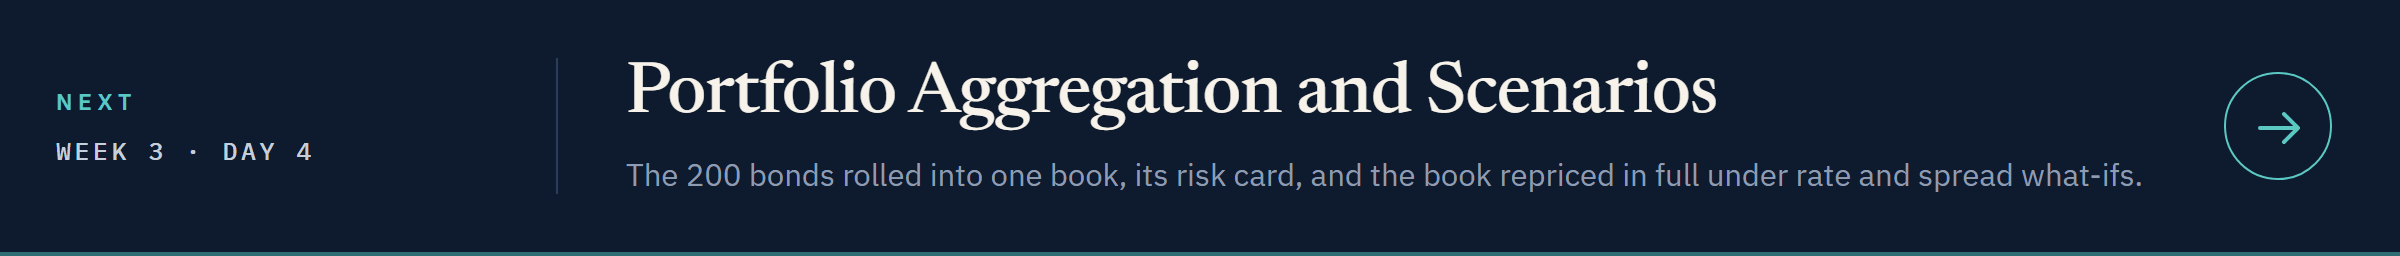](../day4/14_portfolio_aggregation_and_scenarios.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day4/14_portfolio_aggregation_and_scenarios.ipynb)